In [10]:
import sys
!{sys.executable} -m pip install yfinance

  Using cached yfinance-1.8.0-py3-none-any.whl.metadata (6.8 kB)
  Using cached curl_cffi-0.17.0-cp310-abi3-win_amd64.whl.metadata (19 kB)
  Using cached peewee-4.5.3-py3-none-any.whl.metadata (10 kB)
  Using cached cffi-2.1.1-cp313-cp313-win_amd64.whl.metadata (2.6 kB)
Using cached yfinance-1.8.0-py3-none-any.whl (158 kB)
Using cached curl_cffi-0.17.0-cp310-abi3-win_amd64.whl (2.1 MB)
Using cached cffi-2.1.1-cp313-cp313-win_amd64.whl (185 kB)
Using cached peewee-4.5.3-py3-none-any.whl (194 kB)

   ---------------------------------------- 0/4 [peewee]
   ---------------------------------------- 0/4 [peewee]
   ---------------------------------------- 0/4 [peewee]
   ---------------------------------------- 0/4 [peewee]
  Attempting uninstall: cffi
   ---------------------------------------- 0/4 [peewee]
    Found existing installation: cffi 2.0.0
   ---------------------------------------- 0/4 [peewee]
    Uninstalling cffi-2.0.0:
   ---------------------------------------- 0/4 [peewee


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\admin\scoop\apps\python\current\python.exe -m pip install --upgrade pip


In [11]:
import numpy as np
import pandas as pd 
import yfinance as yf
import matplotlib as plt 

import torch 
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
ticker = 'AAPL'
df = yf.download(ticker, '2020-01-01')

[*********************100%***********************]  1 of 1 completed


In [14]:
df

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.216660,72.276770,70.975980,71.228440,135480400
2020-01-03,71.514587,72.271977,71.290978,71.447264,146322800
2020-01-06,72.084412,72.122883,70.389301,70.639362,118387200
2020-01-07,71.745430,72.348934,71.526627,72.094066,108872000
2020-01-08,72.899513,73.200065,71.449650,71.449650,132079200
...,...,...,...,...,...
2026-11-09,350.423737,352.062476,344.518220,344.738054,48753100
2026-11-10,348.245392,353.601307,346.196930,351.083232,29756100


<Axes: xlabel='Date'>

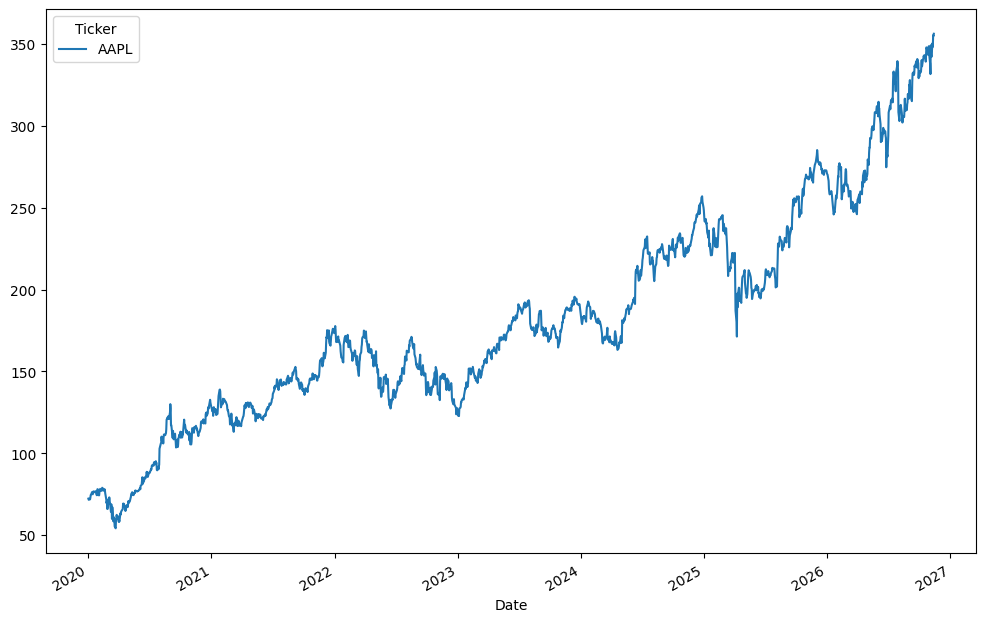

In [21]:
df.Close.plot(figsize=(12, 8))

In [22]:
scaler = StandardScaler()

df['Close'] = scaler.fit_transform(df[['Close']])

In [24]:
df.Close

Ticker,AAPL
Date,
2020-01-02,-1.676816
2020-01-03,-1.687620
2020-01-06,-1.678851
2020-01-07,-1.684068
2020-01-08,-1.666308
...,...
2026-11-09,2.604414
2026-11-10,2.570892
2026-11-11,2.680376


In [25]:
seq_length = 30
data = []

for i in range(len(df) - seq_length):
    data.append(df.Close[i:i+seq_length])

data = np.array(data)

In [26]:
data

array([[[-1.67681625],
        [-1.68762019],
        [-1.67885136],
        ...,
        [-1.60274619],
        [-1.57459527],
        [-1.58323753]],

       [[-1.68762019],
        [-1.67885136],
        [-1.68406783],
        ...,
        [-1.57459527],
        [-1.58323753],
        [-1.58294073]],

       [[-1.67885136],
        [-1.68406783],
        [-1.66630805],
        ...,
        [-1.58323753],
        [-1.58294073],
        [-1.60500872]],

       ...,

       [[ 2.33270263],
        [ 2.29118504],
        [ 2.34300525],
        ...,
        [ 2.47647713],
        [ 2.60441355],
        [ 2.57089178]],

       [[ 2.29118504],
        [ 2.34300525],
        [ 2.33070391],
        ...,
        [ 2.60441355],
        [ 2.57089178],
        [ 2.68037573]],

       [[ 2.34300525],
        [ 2.33070391],
        [ 2.34208291],
        ...,
        [ 2.57089178],
        [ 2.68037573],
        [ 2.67298948]]], shape=(1697, 30, 1))

In [32]:
train_size = int(len(data) * 0.8)

X_train = torch.from_numpy(data[:train_size, :-1, :]).type(torch.Tensor).to(device)
y_train = torch.from_numpy(data[:train_size, -1, :]).type(torch.Tensor).to(device)
X_test = torch.from_numpy(data[train_size:, -1, :]).type(torch.Tensor).to(device)
y_test = torch.from_numpy(data[train_size:, -1, :]).type(torch.Tensor).to(device)

In [33]:
class PredictionModel(nn.Module):
    def __init__(self, input_dim, hidden_size, num_layers, output_dim):
        super(PredictionModel, self).__init__()

        self.num_layers = num_layers
        self.hidden_size = hidden_size

        self.lstm = nn.LSTM(input_dim, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size, device=device)

        out, (hn , cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])
        return out

In [34]:
model = PredictionModel(input_dim=1, hidden_size=32, num_layers=2, output_dim=1).to(device)

In [35]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [36]:
num_epochs = 200

for i in range(num_epochs):
    y_train_pred = model(X_train)

    loss = criterion(y_train_pred, y_train)

    if i % 25 == 0:
        print(i, loss)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    

0 tensor(0.5530, grad_fn=<MseLossBackward0>)
25 tensor(0.0073, grad_fn=<MseLossBackward0>)
50 tensor(0.0050, grad_fn=<MseLossBackward0>)
75 tensor(0.0039, grad_fn=<MseLossBackward0>)
100 tensor(0.0036, grad_fn=<MseLossBackward0>)
125 tensor(0.0033, grad_fn=<MseLossBackward0>)
150 tensor(0.0031, grad_fn=<MseLossBackward0>)
175 tensor(0.0028, grad_fn=<MseLossBackward0>)
